# UFC method of victory

This notebook trains a two-stage model to predict decision, KO/TKO, or submission from information available before a fight. It compares the results with a direct logistic regression, the CatBoost model from PR #1, and a baseline that always picks decision.

From the repository root, install the dependencies in a Python 3.12 environment, then open this notebook in JupyterLab.

```bash
python -m pip install -r requirements.txt numpy==2.3.5 pandas==2.2.3 scikit-learn==1.8.0 catboost==1.2.10 jupyterlab matplotlib
jupyter lab two_stage_predictor.ipynb
```

Run all cells to rebuild the experiment from the committed UFCStats export. Set `RETRAIN = False` to explore the committed results and run the saved model without rebuilding the fight histories.

In [1]:
%matplotlib inline

from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd
from IPython.display import display

from build_dataset import LABEL_MAP
from predict import predict_multimodal
from train import CLASSES
from train_method_rates import OUT, ROOT, load_rows, main as train_and_evaluate

RETRAIN = True
scratch_run = TemporaryDirectory() if RETRAIN else None
results_dir = Path(scratch_run.name) if RETRAIN else OUT

outcome_names = {"DEC": "Decision", "KO/TKO": "KO/TKO", "SUB": "Submission"}
outcome_colors = {"DEC": "#2563A6", "KO/TKO": "#B35D20", "SUB": "#087F72"}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelcolor": "#24364B",
    "axes.titlecolor": "#16273D",
    "axes.axisbelow": True,
    "grid.color": "#DCE3EC",
    "font.size": 10,
})

## Training data and time split

Each row is one fight from the committed UFCStats export. The code keeps bouts with a recorded winner and a result in one of the three modeled classes. It uses the project's label mapping so, for example, doctor stoppages count as KO/TKO.

The model trains on **2010–2023**, model selection uses **2024**, and evaluation uses **2025** and the available **2026** bouts. Using later fights for evaluation tests whether the model transfers to new cards. Only prior dates can contribute fight history to the features. The plots below show the training set's overall balance and how the outcome mix changes by year.

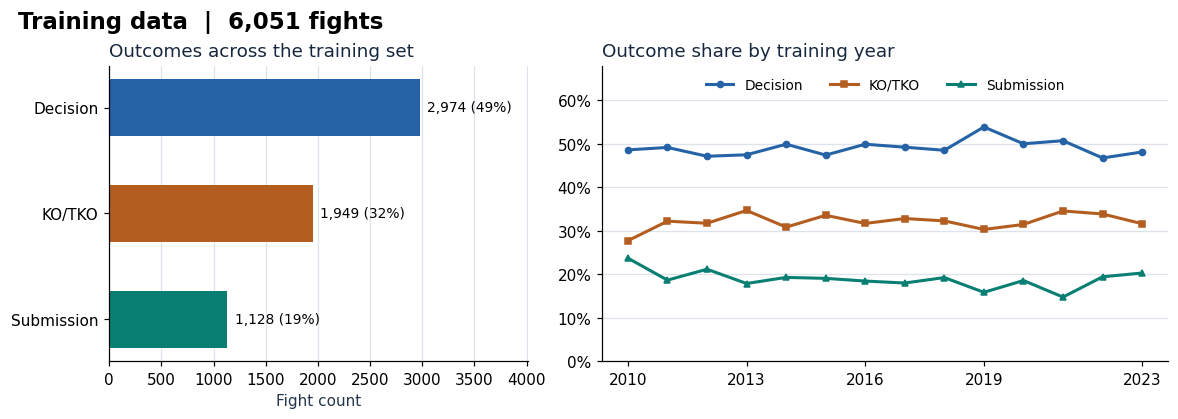

In [2]:
label_rows = pd.read_csv(ROOT / "raw_fights_greco.csv", sep=";", usecols=["date", "Winner", "win_by"])
label_rows["year"] = pd.to_datetime(label_rows["date"], format="mixed").dt.year
label_rows["label"] = label_rows["win_by"].map(LABEL_MAP)
training_labels = label_rows.loc[
    label_rows["year"].between(2010, 2023) & label_rows["Winner"].notna() & label_rows["label"].isin(CLASSES)
]
counts_by_year = pd.crosstab(training_labels["year"], training_labels["label"]).reindex(columns=CLASSES)
training_counts = counts_by_year.sum()
share_by_year = counts_by_year.div(counts_by_year.sum(axis=1), axis=0)

fig, (ax_count, ax_year) = plt.subplots(
    1, 2, figsize=(10.6, 3.7), width_ratios=[1, 1.35], layout="constrained",
)
fig.suptitle(f"Training data  |  {training_counts.sum():,} fights", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
bars = ax_count.barh([outcome_names[label] for label in CLASSES], training_counts,
                      color=[outcome_colors[label] for label in CLASSES], height=0.54)
ax_count.invert_yaxis()
ax_count.set_title("Outcomes across the training set", loc="left", fontsize=12)
ax_count.set_xlabel("Fight count")
ax_count.set_xlim(0, 1.35 * training_counts.max())
ax_count.grid(axis="x")
bar_labels = [f"{n:,} ({n / training_counts.sum():.0%})" for n in training_counts]
ax_count.bar_label(bars, labels=bar_labels, padding=5, fontsize=9)

for label, marker in zip(CLASSES, ("o", "s", "^")):
    ax_year.plot(share_by_year.index, share_by_year[label], color=outcome_colors[label],
                 label=outcome_names[label], marker=marker, markersize=4, linewidth=2)
ax_year.set_title("Outcome share by training year", loc="left", fontsize=12)
ax_year.set_xticks([2010, 2013, 2016, 2019, 2023])
ax_year.set_ylim(0, 0.68)
ax_year.yaxis.set_major_formatter(PercentFormatter(1))
ax_year.grid(axis="y")
ax_year.legend(loc="upper center", ncols=3, frameon=False, fontsize=9)
plt.show()

## Fit the two stages and choose a model

The feature builder summarizes each fighter's previous bouts with results, time since their last fight, and striking and grappling rates per minute. The feature builder uses sums and absolute differences so the result is independent of which athlete is listed first. Each classifier fills missing measurements from its own training examples, scales the features, and fits a regularized logistic regression. [Feature and model code](fight_methods.py)

Stage 1 learns from all training fights and estimates the probability of a finish, $f$. Stage 2 learns from finishes and estimates the probability of a submission given a finish, $s$. Combining them gives three probabilities that sum to one.

| Decision | KO/TKO | Submission |
|---|---|---|
| $1-f$ | $f(1-s)$ | $fs$ |

The training script compares that approach with a single classifier using the same inputs. For each architecture, it tests five class-weight settings on 2024. It picks the setting with the highest macro F1 within two percentage points of that architecture's best validation accuracy. The selected two-stage model divides each class probability by the square root of its training frequency to choose a label. That gives rarer outcomes more weight. The reported probabilities still come directly from the two-stage calculation. [Training code](train_method_rates.py)

The cell writes fresh results to a temporary directory so you can compare them with the files committed to the branch.

In [3]:
if RETRAIN:
    rows = load_rows()
    training_rows = rows.loc[rows["date"].dt.year.between(2010, 2023) & rows["label"].isin(CLASSES)]
    observed_counts = training_rows["label"].value_counts().reindex(CLASSES)
    np.testing.assert_array_equal(observed_counts, training_counts)
    with redirect_stdout(StringIO()):
        train_and_evaluate(rows, output_dir=results_dir)
    del rows, training_rows

scores = pd.read_csv(results_dir / "scores.csv")
validation = scores.loc[scores["year"].eq(2024), ["model", "n", "accuracy", "macro_f1", "sub_caught"]]
display(validation.rename(columns={"model": "Model", "n": "Fights", "accuracy": "Accuracy",
                                  "macro_f1": "Macro F1", "sub_caught": "Submissions caught"})
        .round({"Accuracy": 3, "Macro F1": 3}).reset_index(drop=True))

,Model,Fights,Accuracy,Macro F1,Submissions caught
0,Direct,511,0.532,0.439,15
1,Two-stage,511,0.542,0.446,14


## Accuracy on later fights

The accuracy chart comes from per-fight predictions on the two test periods. The 2025 results include 20 bouts examined earlier in the project. The 2026 evaluation covers the available sample through November 21. The dotted line marks the project's **70% accuracy goal** across all fights.

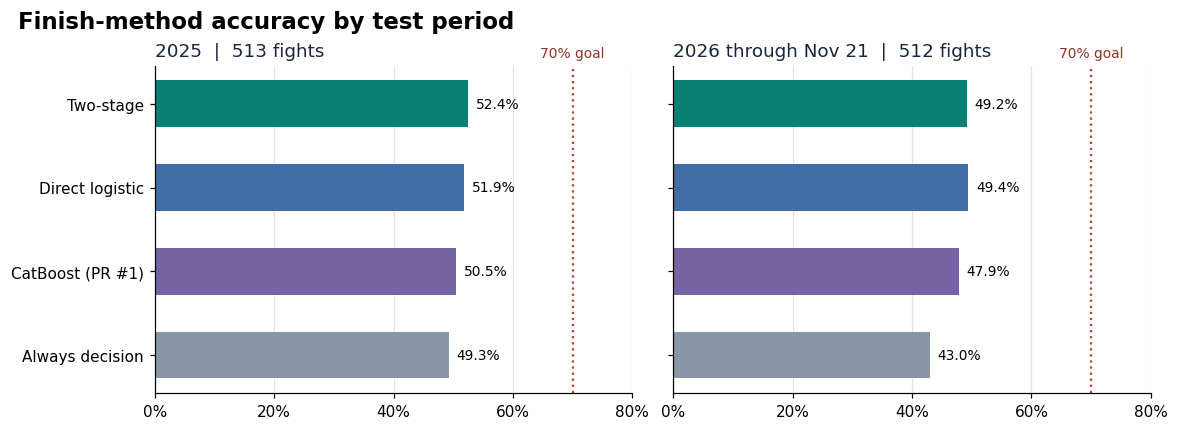

In [4]:
picks = pd.concat(
    [pd.read_csv(results_dir / f"picks_{year}.csv", parse_dates=["date"]) for year in (2025, 2026)],
    ignore_index=True,
)
models = ["Two-stage", "Direct", "PR CatBoost", "Always decision"]
model_colors = ["#087F72", "#416CA5", "#7663A3", "#8896A7"]
model_labels = ["Two-stage", "Direct logistic", "CatBoost (PR #1)", "Always decision"]

fig, axes = plt.subplots(1, 2, figsize=(10.6, 3.8), sharey=True, layout="constrained")
fig.suptitle("Finish-method accuracy by test period", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
for ax, (year, group) in zip(axes, picks.groupby(picks["date"].dt.year)):
    accuracy = [group[model].eq(group["label"]).mean() for model in models]
    bars = ax.barh(model_labels, accuracy, color=model_colors, height=0.56)
    period = "2025" if year == 2025 else "2026 through Nov 21"
    ax.set_title(f"{period}  |  {len(group):,} fights", loc="left", fontsize=12)
    ax.bar_label(bars, labels=[f"{value:.1%}" for value in accuracy], padding=5, fontsize=9)
    ax.axvline(0.70, color="#B34A38", linewidth=1.5, linestyle=":")
    ax.text(0.70, 1.015, "70% goal", color="#8C3326", transform=ax.get_xaxis_transform(),
            ha="center", va="bottom", fontsize=9)
    ax.set_xlim(0, 0.80)
    ax.set_xticks(np.arange(0, 0.81, 0.2))
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="x")
axes[0].invert_yaxis()
plt.show()

## Where each model misses

Each row of a confusion matrix is an actual finish method, and its columns show the model's picks. A diagonal cell counts correct picks. The color shows the share of that actual outcome, so submissions remain visible even though they occur less often.

The table and the interval below use the same 1,025 fights for all models. The interval resamples entire event dates to keep the bouts on each card together while measuring how uncertain the accuracy difference is.

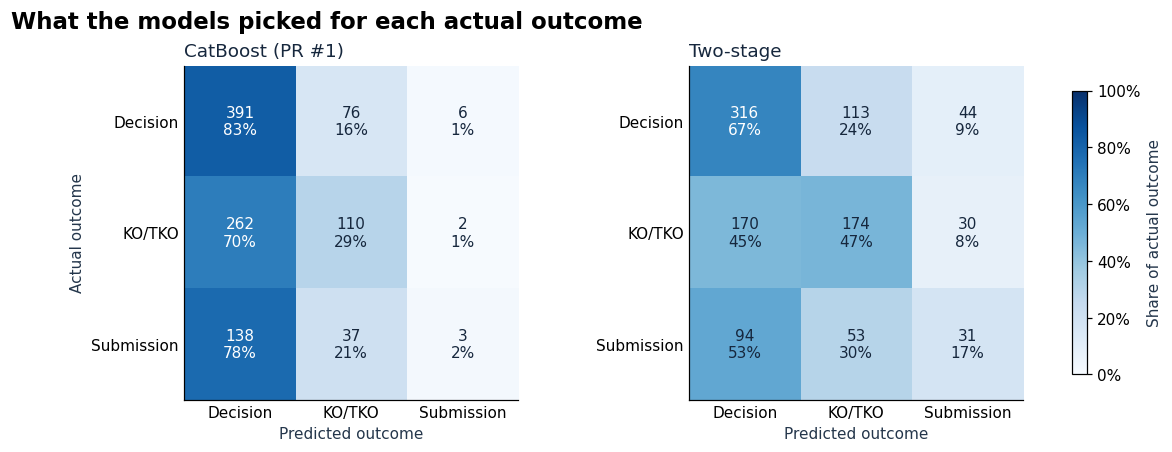

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.0), layout="constrained")
fig.suptitle("What the models picked for each actual outcome", x=0.01, ha="left",
             fontsize=15, fontweight="bold")
tick_labels = [outcome_names[label] for label in CLASSES]
for ax, model in zip(axes, ["PR CatBoost", "Two-stage"]):
    counts = pd.crosstab(picks["label"], picks[model]).reindex(index=CLASSES, columns=CLASSES, fill_value=0)
    shares = counts.div(counts.sum(axis=1), axis=0).to_numpy()
    panel = ax.imshow(shares, cmap="Blues", vmin=0, vmax=1)
    for actual in range(len(CLASSES)):
        for predicted in range(len(CLASSES)):
            fraction = shares[actual, predicted]
            ax.text(predicted, actual, f"{counts.iat[actual, predicted]:,}\n{fraction:.0%}",
                    ha="center", va="center", color="white" if fraction > 0.58 else "#16273D")
    ax.set_title("CatBoost (PR #1)" if model == "PR CatBoost" else model, loc="left", fontsize=12)
    ax.set_xticks(range(len(CLASSES)), tick_labels)
    ax.set_yticks(range(len(CLASSES)), tick_labels)
    ax.tick_params(length=0)
    ax.set_xlabel("Predicted outcome")
axes[0].set_ylabel("Actual outcome")
legend = fig.colorbar(panel, ax=axes, shrink=0.85, format=PercentFormatter(1))
legend.set_label("Share of actual outcome")
plt.show()

In [6]:
submissions = picks["label"].eq("SUB")
records = []
for model, label in zip(models, model_labels):
    correct = picks[model].eq(picks["label"])
    records.append({
        "Model": label, "Correct picks": int(correct.sum()),
        "Accuracy": f"{correct.mean():.1%}",
        "Submissions caught": f"{(correct & submissions).sum()} / {submissions.sum()}",
        "Submission picks": int(picks[model].eq("SUB").sum()),
    })
display(pd.DataFrame(records).set_index("Model"))

difference = (picks["Two-stage"].eq(picks["label"]).astype(int)
              - picks["PR CatBoost"].eq(picks["label"]).astype(int))
dates = difference.groupby(picks["date"]).agg(["sum", "size"])
draws = np.random.default_rng(4397).integers(len(dates), size=(10_000, len(dates)))
bootstrap = dates["sum"].to_numpy()[draws].sum(axis=1) / dates["size"].to_numpy()[draws].sum(axis=1)
low, high = np.quantile(100 * bootstrap, [0.025, 0.975])
print(f"The two-stage model gained {100 * difference.mean():+.1f} percentage points over CatBoost "
      f"(paired 95% interval {low:+.1f} to {high:+.1f}).")

,Correct picks,Accuracy,Submissions caught,Submission picks
Model,,,,
Two-stage,521,50.8%,31 / 178,105
Direct logistic,519,50.6%,28 / 178,105
CatBoost (PR #1),504,49.2%,3 / 178,11
Always decision,473,46.1%,0 / 178,0


The two-stage model gained +1.7 percentage points over CatBoost (paired 95% interval -1.6 to +5.0).


The two-stage model caught **31 of 178 submissions**, compared with **3** for CatBoost. It called submission 105 times, so it still produced 74 false positives. The direct logistic model was close in overall accuracy. The interval includes zero, so more fights are needed to establish an accuracy advantage, and neither model reached the 70% goal.

## Make predictions on a fight card

The repository root contains a 20-fight example in the expected input format. This cell uses the same prediction function as `run.py` and checks that the model reproduces the evaluation picks and rounded probabilities. To score a different card, call `predict_multimodal` with your upload folder and the same model path.

In [7]:
demo = predict_multimodal(ROOT, model_path=results_dir / "selected_model.joblib")
card = pd.read_csv(ROOT / "fights.csv", parse_dates=["date"])
keys = ["date", "R_fighter", "B_fighter"]
demo = demo.merge(card[["sample_id", "date"]], on="sample_id", validate="one_to_one")
checked = demo.merge(picks, on=keys, validate="one_to_one", suffixes=("_demo", "_test"))
assert len(checked) == len(card) == 20
assert checked["predicted"].eq(checked["Two-stage"]).all()
for prob in ["p_DEC", "p_KO/TKO", "p_SUB"]:
    np.testing.assert_allclose(checked[prob + "_demo"], checked[prob + "_test"].round(3), rtol=0, atol=1e-10)
print(f"Verified {len(checked)} picks and {3 * len(checked)} probabilities.")
display(checked[["sample_id", "R_fighter", "B_fighter", "predicted", "label",
                 "p_DEC_demo", "p_KO/TKO_demo", "p_SUB_demo"]].head())

,sample_id,R_fighter,B_fighter,predicted,label,p_DEC_demo,p_KO/TKO_demo,p_SUB_demo
0,P01,Alexandre Pantoja,Kai Kara-France,DEC,SUB,0.522,0.291,0.186
1,P02,Beneil Dariush,Renato Moicano,SUB,DEC,0.394,0.308,0.298
2,P03,Jack Hermansson,Gregory Rodrigues,DEC,KO/TKO,0.505,0.380,0.115
3,P04,Ilia Topuria,Charles Oliveira,SUB,KO/TKO,0.267,0.381,0.352
4,P05,Niko Price,Jacobe Smith,KO/TKO,SUB,0.352,0.488,0.160


Verified 20 picks and 60 probabilities.
